# Actividad 3 · Prototipo por transferencia de aprendizaje (Grupo 9)

**Tarea:** detección de objetos de movilidad urbana desde dron (VisDrone2019-DET) con **YOLO11n** preentrenado en COCO.
Se usa **transferencia de aprendizaje en dos etapas**: primero se entrena la cabeza con el backbone congelado y después se hace un fine-tuning completo.

Este notebook es el **código del fine-tuning** y la fuente de todas las cifras del informe. Contiene:

1. La preparación del dataset, con un split por secuencia que evita fuga de información.
2. Las dos etapas de entrenamiento y las líneas base: COCO sin ajuste, entrenamiento desde cero y fine-tuning en una sola etapa.
3. La evaluación en el split de **test**, que el entrenamiento nunca ve: métricas por clase, matriz de confusión y comparación de modelos.

> Con `RUN_TRAINING = False` el notebook solo carga los artefactos de `runs/act3/` que generó `python -m transfer_learning.experiments all`. Con `True` reentrena todo. En un Apple M4 (MPS) eso toma varias horas.

In [1]:
import json, platform, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "transfer_learning" else Path.cwd()
sys.path.insert(0, str(ROOT))
import os; os.chdir(ROOT)

import torch, ultralytics
from IPython.display import Image, Markdown, display

RUN_PREPARE = False   # rebuild data/visdrone6 from the official zips in data/raw
RUN_TRAINING = False  # retrain every model (hours); False = load runs/act3 artifacts
STAGE1_EPOCHS, STAGE2_EPOCHS = 10, 30

print(f"Python {platform.python_version()} | torch {torch.__version__} | ultralytics {ultralytics.__version__}")
print(f"MPS available: {torch.backends.mps.is_available()} | {platform.machine()} {platform.system()}")

Python 3.12.11 | torch 2.14.1 | ultralytics 8.4.176
MPS available: True | arm64 Darwin


## 1. Datos

**Fuente:** VisDrone2019-DET, con imágenes aéreas tomadas desde dron en 14 ciudades. COCO casi no tiene ese punto de vista, así que hay un **cambio de dominio real** frente al preentrenamiento.

**Clases:** las 10 categorías de VisDrone se agrupan en 6 clases:

| Clase | Categorías de VisDrone |
|---|---|
| person | pedestrian, people |
| bicycle | bicycle |
| car | car, van |
| motorcycle | motor |
| bus | bus |
| truck | truck |

Las seis existen en COCO, lo que permite evaluar el modelo base sin reentrenar.

**Regiones excluidas:** los triciclos, las *ignored regions* y la categoría *others* se rellenan con gris (114). Así no cuentan como positivos ni como falsos positivos.

**Splits:** se usan los oficiales de VisDrone, que provienen de **secuencias de video disjuntas**. Esto funciona como un *group split* y evita que cuadros casi idénticos queden en train y en test a la vez.
- **Train:** subconjunto de 2.000 imágenes, muestreadas en *round-robin* por secuencia para conservar la diversidad de escenas. El límite se debe al disco y al cómputo disponibles.
- **Val:** las 548 imágenes completas. Se usan para seleccionar el mejor *checkpoint*.
- **Test:** las 1.610 imágenes de test-dev completas. Se usan **solo** para el reporte final.

**Preprocesamiento:** las imágenes se reducen a 1024 px en el lado mayor. Ultralytics hace el letterbox a 640 y escala a [0, 1]; YOLO no usa normalización de media y desviación de ImageNet. Las aumentaciones (mosaic, flip horizontal, HSV, escala y traslación) se aplican **solo en train**.

In [2]:
if RUN_PREPARE:
    from transfer_learning.prepare_data import main as prepare
    prepare(["--raw-dir", "data/raw", "--out", "data/visdrone6", "--train-images", "2000"])

stats = json.loads(Path("data/visdrone6/stats.json").read_text())
classes = stats["config"]["classes"]
header = "| Split | Imágenes | " + " | ".join(classes) + " | Total |"
lines = [header, "|" + "---|" * (len(classes) + 3)]
for split in ("train", "val", "test"):
    s = stats[split]
    lines.append(f"| {split} | {s['images']} | " + " | ".join(f"{s['instances'][c]:,}" for c in classes)
                 + f" | {sum(s['instances'].values()):,} |")
display(Markdown("\n".join(lines)))

| Split | Imágenes | person | bicycle | car | motorcycle | bus | truck | Total |
|---|---|---|---|---|---|---|---|---|
| train | 2000 | 43,732 | 4,748 | 58,520 | 12,371 | 1,409 | 3,819 | 124,599 |
| val | 548 | 13,969 | 1,287 | 16,039 | 4,886 | 251 | 750 | 37,182 |
| test | 1610 | 27,382 | 1,302 | 33,845 | 5,845 | 2,940 | 2,659 | 73,973 |

Hay un **desbalance fuerte** entre clases: *car* y *person* dominan, mientras que *bus* y *bicycle* son escasas. Además, muchos objetos miden menos de 20 px en la imagen original. Las dos cosas explican buena parte de los errores que aparecen en la sección 4.

## 2. Transferencia de aprendizaje en dos etapas

El código está en `transfer_learning/experiments.py`. Todas las corridas comparten el dataset, `imgsz=640`, `batch=16`, AdamW (`weight_decay=5e-4`), `seed=0` y el dispositivo MPS.

| Corrida | Inicialización | Capas entrenables | LR | Épocas |
|---|---|---|---|---|
| **Etapa 1** | COCO (`yolo11n.pt`), cabeza nueva de 6 clases | solo cuello + cabeza (`freeze=11`: módulos 0-10 = backbone) | 1e-3, warmup 1 ép. | 10 |
| **Etapa 2** | mejores pesos de la Etapa 1 | todas (`freeze=0`) | 2e-4 → 1e-5, coseno, sin warmup | 30 |
| Desde cero | pesos aleatorios (`yolo11n.yaml`) | todas | 1e-3, warmup 3 ép. | 40 |
| Fine-tuning 1 etapa | COCO | todas | 1e-3, warmup 1 ép. | 40 |
| COCO sin ajuste | COCO, clases mapeadas a ids COCO | — | — | 0 |

**Por qué dos etapas:** la cabeza nueva arranca con pesos aleatorios. Si se descongela todo desde el inicio, sus gradientes grandes llegan al backbone y degradan los filtros preentrenados. En la Etapa 1 se estabiliza la cabeza; en la Etapa 2 se adapta el backbone al dominio aéreo con un LR 5 veces menor.

In [3]:
from transfer_learning import experiments as ex

if RUN_TRAINING:
    base = ex.common_args(device="mps", batch=16, imgsz=640, workers=4)
    ev = {"device": "mps", "batch": 16, "imgsz": 640}
    ex.evaluate("yolo11n.pt", "zeroshot", zeroshot=True, **ev)
    for step, epochs in (("stage1", STAGE1_EPOCHS), ("stage2", STAGE2_EPOCHS),
                         ("scratch", STAGE1_EPOCHS + STAGE2_EPOCHS), ("full_ft", STAGE1_EPOCHS + STAGE2_EPOCHS)):
        getattr(ex, f"train_{step}")(epochs, base)
        ex.evaluate(str(ex.PROJECT / step / "weights" / "best.pt"), step, **ev)

for name in ("stage1", "stage2", "scratch", "full_ft"):
    info_path = ex.PROJECT / name / "train_info.json"
    if info_path.exists():
        info = json.loads(info_path.read_text())
        device = info["args"].get("device")
        print(f"{name:8s} epochs={info['epochs']:3d}  train={info['train_seconds']/60:6.1f} min  device={device}  params={info['params']:,}")
    elif (ex.PROJECT / "eval" / name / "metrics.json").exists():
        print(f"{name:13s} trained on a second machine (GTX 1660 Super); only its test metrics are available here")

stage1   epochs= 10  train=  25.1 min  device=mps  params=2,606,098
stage2   epochs= 30  train=  77.3 min  device=mps  params=2,606,098
scratch  epochs= 40  train=  54.7 min  device=0  params=2,591,010
full_ft  epochs= 40  train=  53.7 min  device=0  params=2,606,098


### Evidencia de transferencia: carga explícita de pesos y congelamiento

Se compara, módulo por módulo, la diferencia máxima absoluta |Δw| entre checkpoints. Las estadísticas de BatchNorm se excluyen porque son *buffers* y no pesos entrenables.
- **COCO (`yolo11n.pt`) → Etapa 1:** los módulos 0-10 (backbone) deben quedar **idénticos** (Δ=0); el cuello y la cabeza cambian.
- **Etapa 1 → Etapa 2:** todos los módulos cambian, porque el fine-tuning es completo.
- **La capa de salida propia:** `Detect` (módulo 23) reemplaza la rama de clasificación de 80 clases de COCO por una de 6 clases inicializada desde cero. Sus convoluciones finales de clase cambiaron de forma, así que no se pueden comparar. En el módulo 23 solo se comparan las ramas de regresión de caja, que se conservan.

In [4]:
drift_frozen = ex.module_drift("yolo11n.pt", str(ex.PROJECT / "stage1" / "weights" / "best.pt"))
drift_ft = ex.module_drift(str(ex.PROJECT / "stage1" / "weights" / "best.pt"), str(ex.PROJECT / "stage2" / "weights" / "best.pt"))
ft = {d["module"]: d["max_abs_diff"] for d in drift_ft}
lines = ["| Módulo | Parámetros | max abs dW COCO→Etapa 1 | max abs dW Etapa 1→Etapa 2 |", "|---|---|---|---|"]
for d in drift_frozen:
    lines.append(f"| {d['module']} {'(backbone)' if d['module'] <= 10 else ''} | {d['params']:,} | {d['max_abs_diff']:.2e} | {ft.get(d['module'], float('nan')):.2e} |")
display(Markdown("\n".join(lines)))
backbone_frozen = all(d["max_abs_diff"] == 0 for d in drift_frozen if d["module"] <= 10)
print("Backbone (modules 0-10) unchanged after stage 1:", backbone_frozen)
Path("runs/act3/eval/module_drift.json").write_text(json.dumps({"coco_to_stage1": drift_frozen, "stage1_to_stage2": drift_ft}, indent=2))

| Módulo | Parámetros | max abs dW COCO→Etapa 1 | max abs dW Etapa 1→Etapa 2 |
|---|---|---|---|
| 0 (backbone) | 464 | 0.00e+00 | 5.47e-02 |
| 1 (backbone) | 4,672 | 0.00e+00 | 3.21e-02 |
| 2 (backbone) | 6,640 | 0.00e+00 | 3.56e-02 |
| 3 (backbone) | 36,992 | 0.00e+00 | 2.87e-02 |
| 4 (backbone) | 26,080 | 0.00e+00 | 3.06e-02 |
| 5 (backbone) | 147,712 | 0.00e+00 | 2.86e-02 |
| 6 (backbone) | 87,040 | 0.00e+00 | 2.22e-02 |
| 7 (backbone) | 295,424 | 0.00e+00 | 1.73e-02 |
| 8 (backbone) | 346,112 | 0.00e+00 | 2.19e-02 |
| 9 (backbone) | 164,608 | 0.00e+00 | 2.04e-02 |
| 10 (backbone) | 249,728 | 0.00e+00 | 2.46e-02 |
| 13  | 111,296 | 1.96e+00 | 2.74e-02 |
| 16  | 32,096 | 1.61e+00 | 3.31e-02 |
| 17  | 36,992 | 1.21e+00 | 2.11e-02 |
| 19  | 86,720 | 1.65e+00 | 2.26e-02 |
| 20  | 147,712 | 1.43e+00 | 4.22e-02 |
| 22  | 378,880 | 1.88e+00 | 3.24e-02 |
| 23  | 445,472 | 2.02e+00 | 7.03e-02 |

Backbone (modules 0-10) unchanged after stage 1: True


3319

### Curvas de entrenamiento (split de validación)

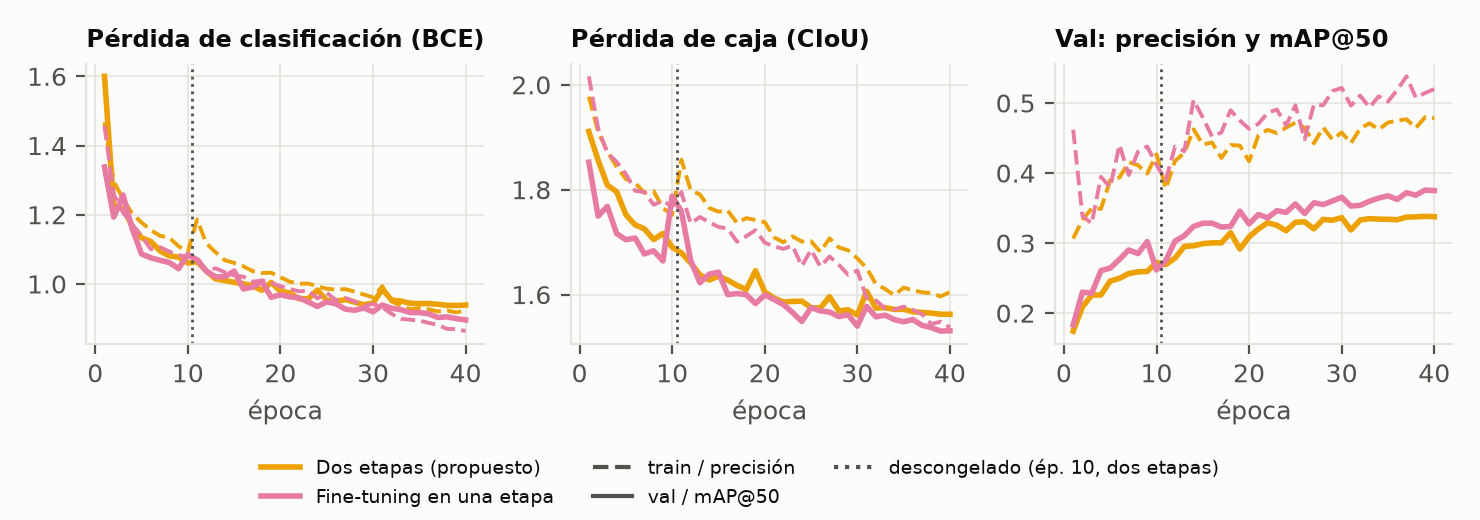

In [5]:
from transfer_learning import figures as fg

FIG = Path("transfer_learning/report/figures"); FIG.mkdir(parents=True, exist_ok=True)
display(Image(str(fg.plot_training_curves(FIG / "curves.png")), width=900))

## 3. Comparación contra los modelos base (split de test)

| Modelo | mAP@50 | mAP@50-95 | Precisión | Recall | Épocas | Mejor época | Entrenamiento (min) | Inferencia (ms/img) |
|---|---|---|---|---|---|---|---|---|
| COCO sin ajuste | 6.2 | 3.1 | 23.3 | 8.8 | 0 | — | 0 | 1.3 |
| Desde cero | 15.5 | 7.3 | 29.5 | 18.3 | 40 | 40 | 55 | 2.9 |
| Etapa 1 (backbone congelado) | 19.2 | 10.0 | 33.5 | 21.8 | 10 | 10 | 25 | 0.7 |
| Dos etapas 10+30 (propuesto) | 24.9 | 13.0 | 39.4 | 26.8 | 40 | 27 | 102 | 0.5 |
| Fine-tuning en una etapa | 26.9 | 14.1 | 42.9 | 28.3 | 40 | 39 | 54 | 2.8 |

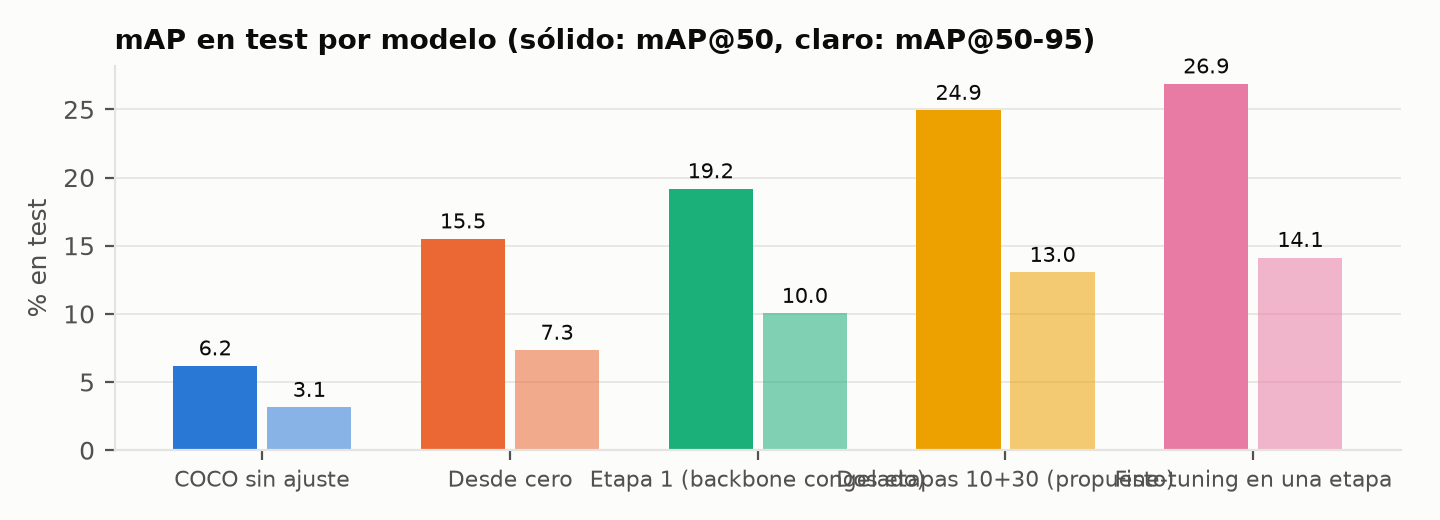

In [6]:
rows = fg.comparison_rows()
lines = ["| Modelo | mAP@50 | mAP@50-95 | Precisión | Recall | Épocas | Mejor época | Entrenamiento (min) | Inferencia (ms/img) |",
         "|---|---|---|---|---|---|---|---|---|"]
for r in rows:
    lines.append(f"| {r['model']} | {r['map50']*100:.1f} | {r['map50_95']*100:.1f} | {r['precision']*100:.1f} | "
                 f"{r['recall']*100:.1f} | {r['epochs']} | {r['best_epoch'] or '—'} | {r['train_min']:.0f} | {r['inference_ms']:.1f} |")
display(Markdown("\n".join(lines)))
display(Image(str(fg.plot_model_comparison(FIG / "comparison.png")), width=900))

### ¿Una etapa o dos?

Para comprobar si congelar primero vale la pena, entrenamos el mismo modelo en una sola etapa: todo descongelado desde el inicio, LR 1e-3 y las mismas 40 épocas en total. Esta corrida se hizo en una GTX 1660 Super, con el mismo código, los mismos datos y la misma semilla.

In [7]:
import numpy as np
s1c, s2c, ffc = fg.load_curve("stage1"), fg.load_curve("stage2"), fg.load_curve("full_ft")
two = np.concatenate([s1c["metrics/mAP50(B)"], s2c["metrics/mAP50(B)"]])
one = ffc["metrics/mAP50(B)"]
print(f"Validation mAP@50: one stage above two stages in {int((one > two).sum())} of {len(one)} epochs")
for name in ("stage2", "full_ft"):
    e = fg.load_eval(name)
    print(f"{fg.LABELS[name]:32s} test mAP@50={e['map50']*100:5.1f}  mAP@50-95={e['map50_95']*100:5.1f}")
e2, eff = fg.load_eval("stage2"), fg.load_eval("full_ft")
print("Classes where one stage wins:", [c for c in e2["per_class"] if eff["per_class"][c]["map50"] > e2["per_class"][c]["map50"]])

Validation mAP@50: one stage above two stages in 39 of 40 epochs
Dos etapas 10+30 (propuesto)     test mAP@50= 24.9  mAP@50-95= 13.0
Fine-tuning en una etapa         test mAP@50= 26.9  mAP@50-95= 14.1
Classes where one stage wins: ['person', 'bicycle', 'car', 'motorcycle', 'bus', 'truck']


### Brecha entre train, val y test (control de sobreajuste)

Las métricas se calculan con los mejores pesos de cada modelo sobre los tres splits, sin aumentación.

In [8]:
gap_path = Path("runs/act3/eval/split_gap.json")
if RUN_TRAINING or not gap_path.exists():
    ex.split_gap(tuple(n for n in ("stage1", "stage2", "scratch", "full_ft") if (ex.PROJECT / n / "weights" / "best.pt").exists()),
                 device="mps", batch=16, imgsz=640)
gap = json.loads(gap_path.read_text())
lines = ["| Modelo | mAP@50 train | mAP@50 val | mAP@50 test | brecha train−test (pp) |", "|---|---|---|---|---|"]
for name, g in gap.items():
    lines.append(f"| {fg.LABELS[name]} | {g['train']['map50']*100:.1f} | {g['val']['map50']*100:.1f} | {g['test']['map50']*100:.1f} | "
                 f"{(g['train']['map50']-g['test']['map50'])*100:+.1f} |")
display(Markdown("\n".join(lines)))

| Modelo | mAP@50 train | mAP@50 val | mAP@50 test | brecha train−test (pp) |
|---|---|---|---|---|
| Etapa 1 (backbone congelado) | 28.5 | 26.5 | 19.2 | +9.3 |
| Dos etapas 10+30 (propuesto) | 39.6 | 32.9 | 24.9 | +14.7 |
| Desde cero | 23.3 | 21.7 | 15.5 | +7.8 |
| Fine-tuning en una etapa | 44.1 | 36.8 | 26.8 | +17.3 |

## 4. Métricas por clase y matriz de confusión del modelo propuesto

| Clase | Precisión | Recall | F1 | AP@50 | AP@50-95 | AP@50 COCO sin ajuste | Instancias |
|---|---|---|---|---|---|---|---|
| person | 0.466 | 0.171 | 0.250 | 0.170 | 0.061 | 0.073 | 27,382 |
| bicycle | 0.270 | 0.040 | 0.070 | 0.047 | 0.017 | 0.008 | 1,302 |
| car | 0.541 | 0.623 | 0.579 | 0.609 | 0.341 | 0.200 | 33,845 |
| motorcycle | 0.324 | 0.201 | 0.248 | 0.159 | 0.054 | 0.022 | 5,845 |
| bus | 0.511 | 0.329 | 0.400 | 0.323 | 0.205 | 0.027 | 2,940 |
| truck | 0.252 | 0.246 | 0.249 | 0.187 | 0.104 | 0.041 | 2,659 |
| **media (macro)** | 0.394 | 0.268 | — | 0.249 | 0.130 | 0.062 | — |

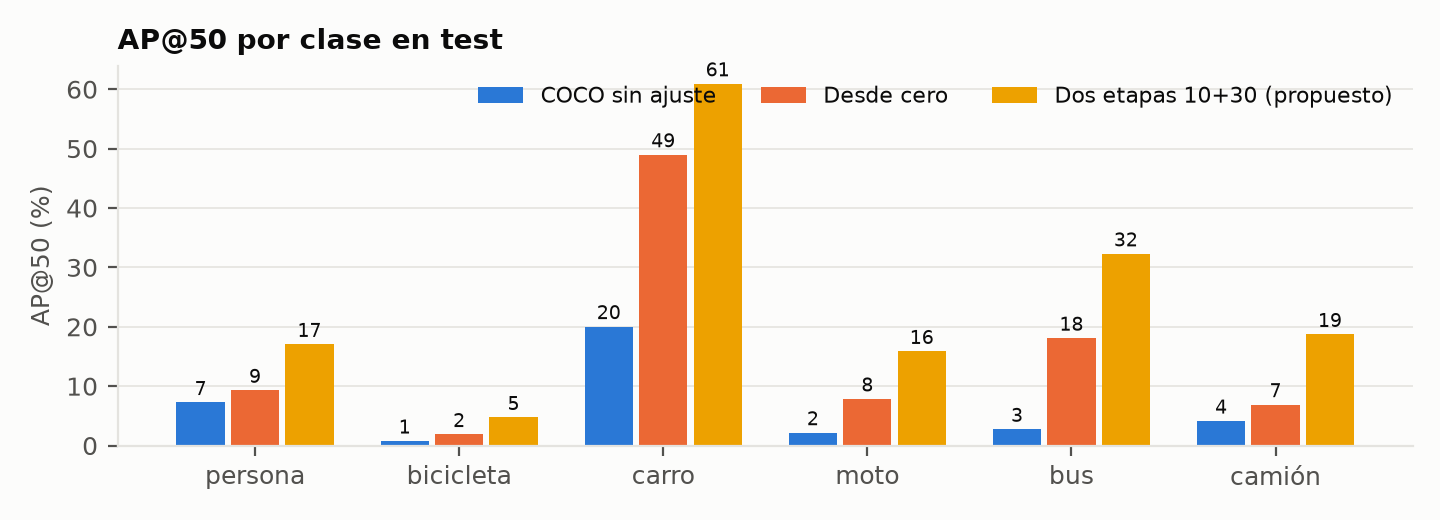

In [9]:
ev2, ev0 = fg.load_eval("stage2"), fg.load_eval("zeroshot")
lines = ["| Clase | Precisión | Recall | F1 | AP@50 | AP@50-95 | AP@50 COCO sin ajuste | Instancias |", "|---|---|---|---|---|---|---|---|"]
for c, m in ev2["per_class"].items():
    lines.append(f"| {c} | {m['precision']:.3f} | {m['recall']:.3f} | {m['f1']:.3f} | {m['map50']:.3f} | {m['map50_95']:.3f} | "
                 f"{ev0['per_class'][c]['map50']:.3f} | {m['support']:,} |")
lines.append(f"| **media (macro)** | {ev2['precision']:.3f} | {ev2['recall']:.3f} | — | {ev2['map50']:.3f} | {ev2['map50_95']:.3f} | {ev0['map50']:.3f} | — |")
display(Markdown("\n".join(lines)))
display(Image(str(fg.plot_per_class(FIG / "per_class.png")), width=900))

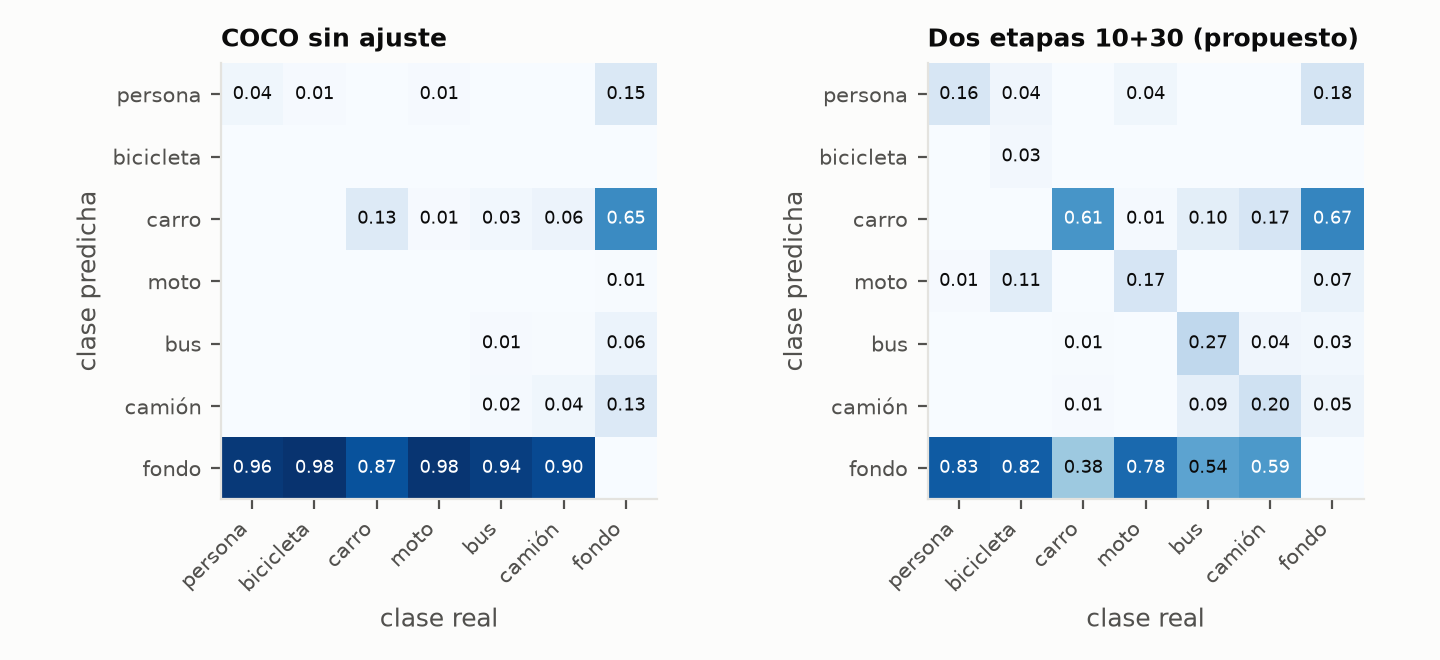

Confusion matrix @ conf=0.25, IoU=0.45; columns = true class (normalized).
Top class-to-class confusions (pred <- true): [(445, 'car', 'truck'), (385, 'truck', 'car'), (290, 'car', 'bus'), (260, 'truck', 'bus'), (226, 'motorcycle', 'person')]
Missed (pred background) per class: {'person': 22832, 'bicycle': 1073, 'car': 12727, 'motorcycle': 4558, 'bus': 1601, 'truck': 1569}
False positives on background per class: {'person': 3159, 'bicycle': 55, 'car': 11814, 'motorcycle': 1205, 'bus': 522, 'truck': 894}


In [10]:
display(Image(str(fg.plot_confusion(FIG / "confusion.png")), width=900))
cm = ev2["confusion_matrix"]
print(f"Confusion matrix @ conf={cm['conf_threshold']}, IoU={cm['iou_threshold']}; columns = true class (normalized).")
labels, M = cm["labels"], fg.np.array(cm["matrix"])
off = [(int(M[r, c]), labels[r], labels[c]) for r in range(len(labels) - 1) for c in range(len(labels) - 1) if r != c]
print("Top class-to-class confusions (pred <- true):", sorted(off, reverse=True)[:5])
print("Missed (pred background) per class:", {labels[c]: int(M[-1, c]) for c in range(len(labels) - 1)})
print("False positives on background per class:", {labels[r]: int(M[r, -1]) for r in range(len(labels) - 1)})

### Ejemplos cualitativos (test)

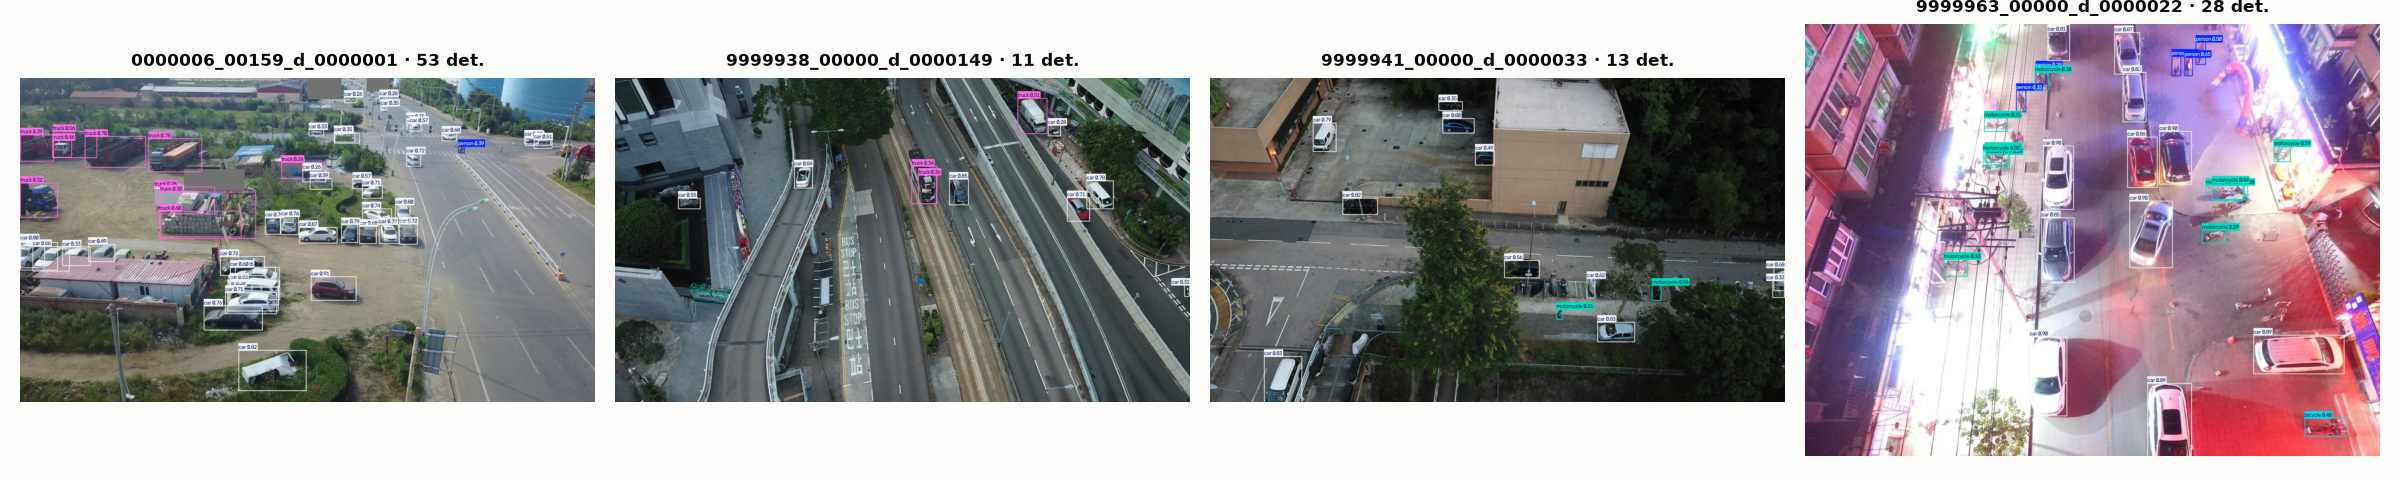

In [11]:
from ultralytics import YOLO
import cv2, matplotlib.pyplot as plt

model = YOLO(str(ex.PROJECT / "stage2" / "weights" / "best.pt"))
samples = sorted(Path("data/visdrone6/images/test").glob("*.jpg"))[::400][:4]
fig, axes = plt.subplots(1, len(samples), figsize=(16, 3.2))
for ax, path in zip(axes, samples):
    res = model.predict(str(path), imgsz=640, conf=0.25, device="mps", verbose=False)[0]
    ax.imshow(cv2.cvtColor(res.plot(line_width=1, font_size=6), cv2.COLOR_BGR2RGB)); ax.axis("off")
    ax.set_title(f"{path.stem} · {len(res.boxes)} det.", fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "qualitative.png", dpi=150); plt.close(fig)
display(Image(str(FIG / "qualitative.png"), width=1000))

### Revisión de los falsos positivos

Se toman las imágenes de test con más falsos positivos. En verde está la verdad anotada; en rojo, las predicciones con conf ≥ 0,25 que no coinciden con ninguna caja anotada (IoU < 0,45).

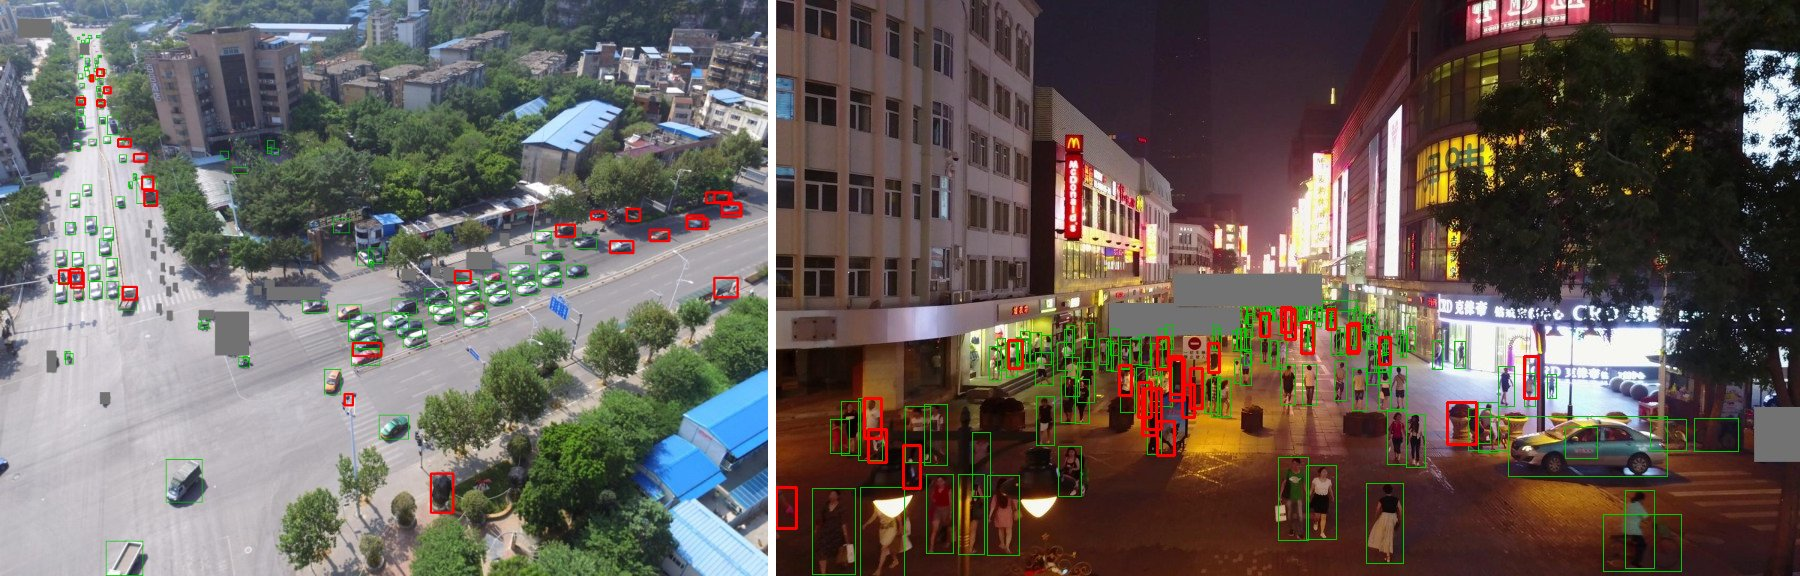

In [12]:
fp_fig = fg.render_false_positives(str(ex.PROJECT / "stage2" / "weights" / "best.pt"), FIG / "false_positives.jpg")
display(Image(str(fp_fig), width=1000))

La mayoría de las cajas rojas son **objetos reales sin anotar**: carros en vías lejanas del fondo y personas dentro de multitudes nocturnas. Las demás caen sobre objetos con silueta parecida (papeleras, troncos, postes). La precisión medida subestima la real; el error dominante es el recall de objetos pequeños.

## 5. Conclusiones

Las conclusiones, junto con las cifras de las tablas anteriores, se discuten en el informe (`transfer_learning/report/Informe_Actividad3_G9.pdf`).